# 04 — Linear Regression & Gradient Descent

**Session 04**

In this notebook we build intuition for **linear regression** and **gradient descent (GD)** using:
1. A **toy 1-feature problem**.
2. A **visual, animated** GD.
3. A real dataset (**California Housing**) to train linear regression with GD and see **why feature scaling matters**.

> Notation: $h_\theta(x) = \theta_0 + \theta_1 x$,
> loss $J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} \big(h_\theta(x^{(i)}) - y^{(i)}\big)^2$.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display, clear_output

# Global plot styling
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

# Fixed seed for reproducibility
np.random.seed(42)

## 1. A toy problem we can *see*

We generate $m = 50 $ points from
$ y = 1 + 2x + \varepsilon,\quad \varepsilon \sim \mathcal{N}(0, 0.2^2) $

so the *true* parameters are $( \theta_0 = 1, \theta_1 = 2 )$.

Because there is only **one feature**, the loss $J(\theta_0, \theta_1)$ lives in 2-D parameter space — we can plot it fully.

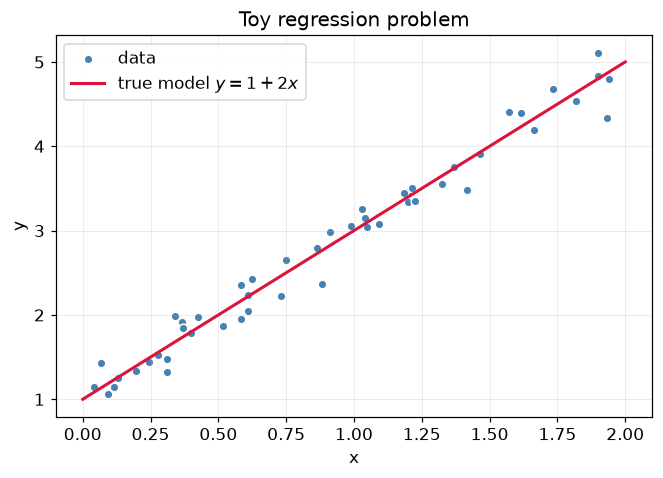

In [17]:
m = 50
x = 2 * np.random.rand(m, 1)                        # x in [0, 2]
y = 1.0 + 2.0 * x + 0.2 * np.random.randn(m, 1)     # true params: theta0=1, theta1=2

X = np.c_[np.ones((m, 1)), x]                       # design matrix with intercept column
theta_true = np.array([[1.0], [2.0]])               # why we converted python list to numpy array? can it also effect on overal time complexity?

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x, y, s=32, color="steelblue", edgecolor="white", label="data")
xs = np.linspace(0, 2, 100)
ax.plot(xs, theta_true[0][0] + theta_true[1][0] * xs,
        color="crimson", linewidth=2, label=r"true model $y = 1 + 2x$")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Toy regression problem")
ax.legend()
plt.show()

## 2. The loss function $J(\theta)$

Please write Python code for *J()* and *grad()* functions w.r.t their mathematical definitions below.

For linear regression with squared error:
$ J(\theta) = \frac{1}{2m}\,\| X\theta - y \|^2 $

Gradient:
$ \nabla_\theta J(\theta) = \frac{1}{m}\,X^\top (X\theta - y) $

In [18]:
# def J(theta, X, y):

# def grad(theta, X, y):


### 2.1 The loss surface in 3-D

Every point $(\theta_0, \theta_1)$ is a candidate model; its height is the loss.

We build the surface analytically using the quadratic form
$ J(\theta) = \tfrac{1}{2}\,\theta^\top H\,\theta - b^\top \theta + c,
\quad H = \tfrac{1}{m} X^\top X,\;\; b = \tfrac{1}{m} X^\top y,\;\; c = \tfrac{1}{2m}\|y\|^2. $

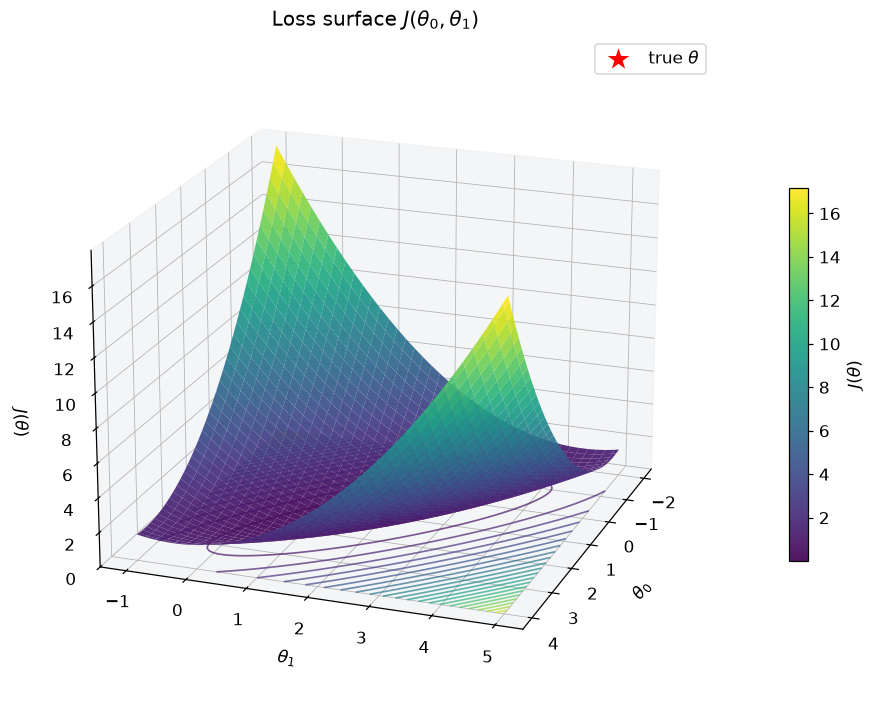

In [19]:
def loss_surface(T0, T1, X, y):
    m = len(y)
    H = (X.T @ X) / m
    b = (X.T @ y).ravel() / m
    c = 0.5 * np.sum(y ** 2) / m
    Z = 0.5 * (H[0,0]*T0**2 + 2*H[0,1]*T0*T1 + H[1,1]*T1**2) \
        - b[0]*T0 - b[1]*T1 + c
    return Z

# grid in parameter space
t0 = np.linspace(-2, 4, 80)
t1 = np.linspace(-1, 5, 80)
T0, T1 = np.meshgrid(t0, t1)
Z = loss_surface(T0, T1, X, y)

# --- 3D surface
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    T0, T1, Z,
    cmap="viridis", linewidth=0, antialiased=True,
    rstride=2, cstride=2, alpha=0.92,
)

# floor contour projection (classic "Andrew Ng" look)
ax.contour(T0, T1, Z, zdir="z", offset=0.0,
           levels=25, cmap="viridis", linewidths=1.1, alpha=0.7)

# true minimum
ax.scatter(*theta_true.ravel(), J(theta_true, X, y),
           marker="*", s=350, color="red", edgecolor="white",
           linewidth=1.2, label=r"true $\theta$")

ax.set_xlabel(r"$\theta_0$", labelpad=8)
ax.set_ylabel(r"$\theta_1$", labelpad=8)
ax.set_zlabel(r"$J(\theta)$", labelpad=8)
ax.set_zlim(0, Z.max() * 1.02)
ax.set_title(r"Loss surface $J(\theta_0, \theta_1)$")
ax.view_init(elev=20, azim=20)
ax.legend(loc="upper right")
fig.colorbar(surf, shrink=0.55, pad=0.08, label=r"$J(\theta)$")
plt.show()

### 2.2 Looking from above: contours

Contours are **iso-loss curves** — walking perpendicular to them = walking downhill.

The minimum sits inside the innermost ellipse; here it is very close to $\theta = (1, 2) $.

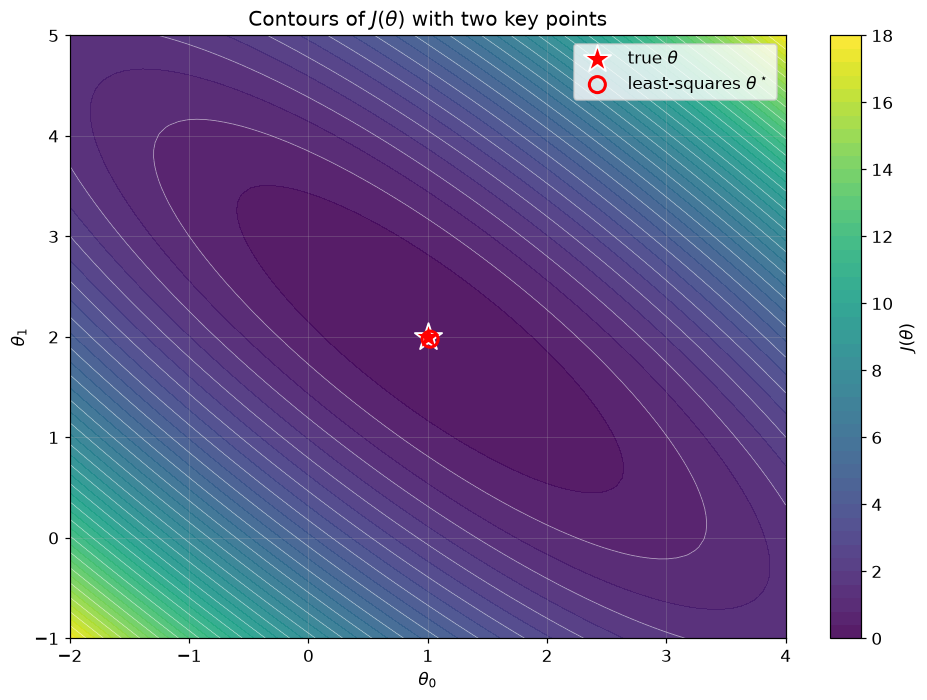

Least-squares optimum θ* = (1.0193, 1.9777)


In [20]:
fig, ax = plt.subplots(figsize=(9, 6.5))

cf = ax.contourf(T0, T1, Z, levels=50, cmap="viridis", alpha=0.9)
ax.contour(T0, T1, Z, levels=25, colors="white", linewidths=0.5, alpha=0.65)

# true parameters
ax.scatter([theta_true[0,0]], [theta_true[1,0]],
           marker="*", s=350, color="red", edgecolor="white", linewidth=1.2,
           zorder=5, label=r"true $\theta$")

# closed-form optimum for *this* data
theta_star = np.linalg.solve(X.T @ X, X.T @ y)
ax.scatter([theta_star[0,0]], [theta_star[1,0]],
           marker="o", s=110, facecolor="none", edgecolor="red", linewidth=2,
           zorder=6, label=r"least-squares $\theta^\star$")

ax.set_xlabel(r"$\theta_0$"); ax.set_ylabel(r"$\theta_1$")
ax.set_title(r"Contours of $J(\theta)$ with two key points")
ax.legend(loc="upper right")
fig.colorbar(cf, ax=ax, label=r"$J(\theta)$")
plt.tight_layout()
plt.show()

print(f"Least-squares optimum θ* = ({theta_star[0,0]:.4f}, {theta_star[1,0]:.4f})")

## 3. Gradient descent from scratch

**Idea:** start at some $\theta^{(0)}$, repeatedly step *against the gradient*:
$\theta^{(k+1)} = \theta^{(k)} - \eta \,\nabla J(\theta^{(k)})$

- $\eta$ = **learning rate**
- $\nabla J(\theta) = \frac{1}{m}X^\top (X\theta - y)$

In [21]:
def gd(X, y, theta_init, lr, n_iter):
    theta = theta_init.copy().astype(float)
    path = [theta_init.copy()]
    losses = [J(theta, X, y)]
    for _ in range(n_iter):
        theta = theta - lr * grad(theta, X, y)
        path.append(theta.copy())
        losses.append(J(theta.copy(), X, y))

    return np.array(path), np.array(losses)


In [22]:
theta_init = np.array([[3.0], [4.0]])
path, losses = gd(X, y, theta_init, lr=0.15, n_iter=100)

# mini "training log"
for i in range(0, len(losses), 5):
    print(f"iter {i:3d} | J = {losses[i]:.6f} | θ = ({path[i,0].item():.3f}, {path[i,1].item():.3f})")
print(f"final  | J = {losses[-1]:.6f} | θ = ({path[-1,0].item():.3f}, {path[-1,1].item():.3f})")

iter   0 | J = 7.845843 | θ = (3.000, 4.000)
iter   5 | J = 0.260072 | θ = (1.403, 2.302)
iter  10 | J = 0.024253 | θ = (1.118, 2.006)
iter  15 | J = 0.016875 | θ = (1.064, 1.957)
iter  20 | J = 0.016607 | θ = (1.051, 1.952)
iter  25 | J = 0.016569 | θ = (1.046, 1.954)
iter  30 | J = 0.016545 | θ = (1.042, 1.956)
iter  35 | J = 0.016526 | θ = (1.040, 1.959)
iter  40 | J = 0.016511 | θ = (1.037, 1.961)
iter  45 | J = 0.016500 | θ = (1.035, 1.963)
iter  50 | J = 0.016492 | θ = (1.033, 1.965)
iter  55 | J = 0.016485 | θ = (1.032, 1.966)
iter  60 | J = 0.016480 | θ = (1.030, 1.968)
iter  65 | J = 0.016475 | θ = (1.029, 1.969)
iter  70 | J = 0.016472 | θ = (1.028, 1.970)
iter  75 | J = 0.016470 | θ = (1.027, 1.971)
iter  80 | J = 0.016468 | θ = (1.026, 1.972)
iter  85 | J = 0.016467 | θ = (1.025, 1.972)
iter  90 | J = 0.016465 | θ = (1.024, 1.973)
iter  95 | J = 0.016464 | θ = (1.024, 1.974)
iter 100 | J = 0.016464 | θ = (1.023, 1.974)
final  | J = 0.016464 | θ = (1.023, 1.974)


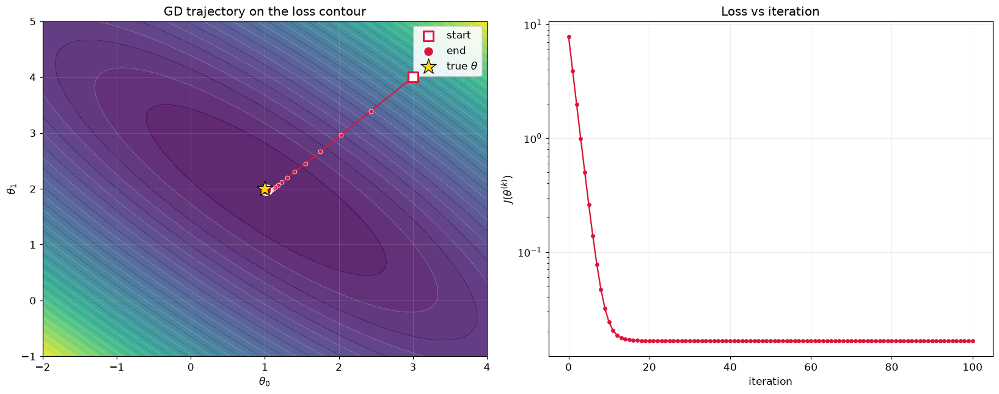

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# --- left: GD path on contours
ax1.contourf(T0, T1, Z, levels=50, cmap="viridis", alpha=0.85)
ax1.contour(T0, T1, Z, levels=25, colors="white", linewidths=0.4, alpha=0.55)
ax1.plot(path[:, 0], path[:, 1], "-", color="crimson", linewidth=1.6, alpha=0.9)
ax1.scatter(path[:, 0], path[:, 1], s=20, color="crimson",
            edgecolor="white", linewidth=0.5, zorder=4)
ax1.scatter([path[0, 0]], [path[0, 1]], marker="s", s=120,
            facecolor="white", edgecolor="crimson", linewidth=2, zorder=6, label="start")
ax1.scatter([path[-1, 0]], [path[-1, 1]], marker="o", s=120,
            facecolor="crimson", edgecolor="white", linewidth=1.5, zorder=6, label="end")
ax1.scatter([theta_true[0,0]], [theta_true[1,0]], marker="*", s=300,
            color="gold", edgecolor="k", linewidth=0.8, zorder=7, label=r"true $\theta$")
ax1.set_xlabel(r"$\theta_0$"); ax1.set_ylabel(r"$\theta_1$")
ax1.set_title("GD trajectory on the loss contour")
ax1.legend(loc="upper right", framealpha=0.9)

# --- right: loss vs iteration
ax2.plot(losses, "o-", color="crimson", markersize=3.5, linewidth=1.5)
ax2.set_xlabel("iteration"); ax2.set_ylabel(r"$J(\theta^{(k)})$")
ax2.set_title("Loss vs iteration")
ax2.set_yscale("log")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 3.1 Watch GD in action

The animation below steps through the same trajectory on the contour plot.

- red trail = the current $\theta^{(k)}$ at each iteration
- right panel = the decreasing loss

In [24]:
# more iterations for a nicer animation
path_anim, losses_anim = gd(X, y, theta_init, lr=0.15, n_iter=80)

fig, (ax_path, ax_loss) = plt.subplots(
    1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.15, 1]}
)

# --- background
ax_path.contourf(T0, T1, Z, levels=50, cmap="viridis", alpha=0.85)
ax_path.contour(T0, T1, Z, levels=25, colors="white", linewidths=0.4, alpha=0.55)
ax_path.scatter([theta_true[0,0]], [theta_true[1,0]], marker="*", s=320,
                color="gold", edgecolor="k", zorder=5, label=r"true $\theta$")
ax_path.set_xlabel(r"$\theta_0$"); ax_path.set_ylabel(r"$\theta_1$")
ax_path.legend(loc="upper right")

trail, = ax_path.plot([], [], "-", color="crimson", linewidth=1.4, alpha=0.9)
dots,  = ax_path.plot([], [], "o", color="crimson", markersize=4, alpha=0.9)
head,  = ax_path.plot([], [], "o", color="crimson", markersize=11,
                      markeredgecolor="white", markeredgewidth=1.5)

# --- loss curve
ax_loss.set_xlim(0, len(losses_anim) - 1)
ax_loss.set_ylim(max(losses_anim.min() * 0.8, 1e-3), losses_anim.max() * 1.1)
ax_loss.set_yscale("log")
ax_loss.set_xlabel("iteration"); ax_loss.set_ylabel(r"$J(\theta^{(k)})$")
ax_loss.set_title("Loss vs iteration")
loss_line, = ax_loss.plot([], [], "-", color="crimson", linewidth=1.5)
loss_head, = ax_loss.plot([], [], "o", color="crimson", markersize=8,
                          markeredgecolor="white")

def init():
    trail.set_data([], []); dots.set_data([], []); head.set_data([], [])
    loss_line.set_data([], []); loss_head.set_data([], [])
    return trail, dots, head, loss_line, loss_head

def update(k):
    trail.set_data(path_anim[:k+1, 0], path_anim[:k+1, 1])
    dots.set_data(path_anim[:k+1, 0], path_anim[:k+1, 1])
    head.set_data([path_anim[k, 0]], [path_anim[k, 1]])
    loss_line.set_data(np.arange(k+1), losses_anim[:k+1])
    loss_head.set_data([k], [losses_anim[k]])
    ax_path.set_title(f"GD · iter {k:2d} · J = {losses_anim[k]:.5f}")
    return trail, dots, head, loss_line, loss_head

anim = FuncAnimation(fig, update, frames=len(path_anim),
                     init_func=init, interval=110, blit=False, repeat=False)
plt.close(fig)
HTML(anim.to_jshtml(fps=10))

## 4. Learning rate matters

- **too small** → slow but stable
- **too large** → overshoots, can diverge

Below we *sweep* $\eta$ and overlay the four trajectories on the same contour.

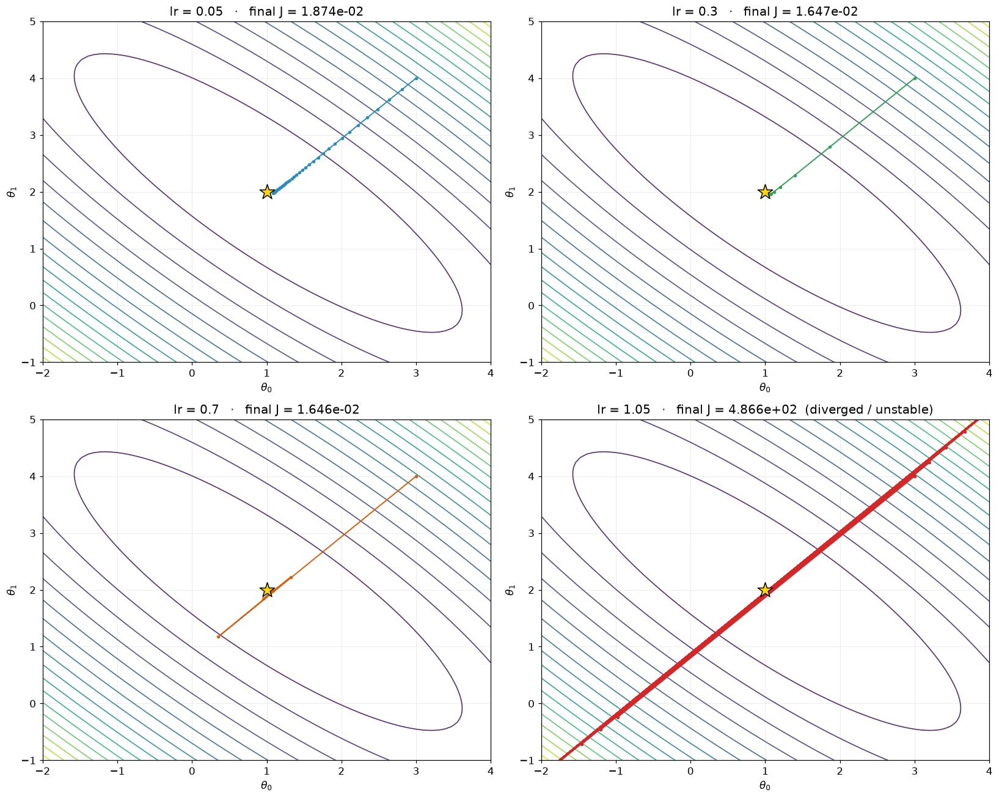

In [26]:
learning_rates = [0.05, 0.3, 0.7, 1.05]
colors = ["#2b8cbe", "#31a354", "#d95f0e", "#d62728"]

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, lr, col in zip(axes.ravel(), learning_rates, colors):
    path_lr, losses_lr = gd(X, y, theta_init, lr=lr, n_iter=40)

    # --- FIX: Ensure 2D shape (n_steps, 2) and 1D losses ---
    path_lr = np.asarray(path_lr).reshape(-1, 2)
    losses_lr = np.asarray(losses_lr).ravel()

    # clip visible path if it diverges
    mask = np.isfinite(path_lr).all(axis=1) & (np.abs(path_lr).max(axis=1) < 20)
    p = path_lr[mask]

    ax.contour(T0, T1, Z, levels=20, cmap="viridis", linewidths=1.1, alpha=0.9)
    ax.plot(p[:, 0], p[:, 1], ".-", color=col, linewidth=1.3, markersize=5)
    ax.scatter([theta_true[0, 0]], [theta_true[1, 0]], marker="*", s=280,
               color="gold", edgecolor="k", zorder=5)

    final_loss = losses_lr[-1] if np.isfinite(losses_lr[-1]) else np.inf
    title = f"lr = {lr}   ·   final J = {final_loss:.3e}"
    if not np.isfinite(final_loss) or final_loss > losses_lr[0] * 2:
        title += "  (diverged / unstable)"
    ax.set_title(title)
    ax.set_xlabel(r"$\theta_0$"); ax.set_ylabel(r"$\theta_1$")
    ax.set_xlim(-2, 4); ax.set_ylim(-1, 5)

plt.tight_layout()
plt.show()


## 5. A real dataset: California Housing

- ~20,600 blocks, 8 features per block
- target: **median house value** (in $100k units)
- we add a column of ones as the **intercept term**

The dataset is bundled with scikit-learn; the first call may take a few seconds.

In [27]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing(as_frame=True)
df = housing.frame
print("shape:", df.shape)
df.head()

shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [28]:
X_cal = df.drop(columns="MedHouseVal").values
y_cal = df["MedHouseVal"].values.reshape(-1, 1)

X_tr, X_te, y_tr, y_te = train_test_split(X_cal, y_cal, test_size=0.2, random_state=42)

X_tr_b = np.c_[np.ones((X_tr.shape[0], 1)), X_tr]
X_te_b = np.c_[np.ones((X_te.shape[0], 1)), X_te]

print("features:", df.drop(columns="MedHouseVal").columns.tolist())
print("X_tr shape:", X_tr_b.shape, "| y_tr range:", (float(y_tr.min()), float(y_tr.max())))

features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
X_tr shape: (16512, 9) | y_tr range: (0.14999, 5.00001)


## 6. Training linear regression with GD on real data

Same code path as the toy problem — `J()` and `grad()` already work. Only the size of $X$ changed.

We train on **standardized** inputs first, and log the loss history.

In [29]:
def train_gd(X, y, lr=0.1, n_iter=500, verbose_every=None):
    theta = np.zeros((X.shape[1], 1))
    losses = [J(theta, X, y)]
    for i in range(n_iter):
        theta = theta - lr * grad(theta, X, y)
        j = J(theta, X, y)
        if not np.isfinite(j) or j > 1e12:
            if verbose_every: print(f"[diverged] at iter {i}")
            break
        losses.append(j)
        if verbose_every and i % verbose_every == 0:
            print(f"iter {i:4d} | J = {j:.5f}")
    return theta, np.array(losses)

# --- scaled path
scaler = StandardScaler().fit(X_tr)

X_tr_scaled = scaler.transform(X_tr)
X_tr_scaled = np.c_[np.ones((X_tr_scaled.shape[0], 1)), X_tr_scaled]
X_te_scaled = scaler.transform(X_te)
X_te_scaled = np.c_[np.ones((X_te_scaled.shape[0], 1)), X_te_scaled]

theta_scaled, losses_scaled = train_gd(X_tr_scaled, y_tr, lr=0.1, n_iter=400, verbose_every=50)
print(f"final training loss (scaled): {losses_scaled[-1]:.5f}")

iter    0 | J = 2.33886
iter   50 | J = 0.29077
iter  100 | J = 0.27353
iter  150 | J = 0.26578
iter  200 | J = 0.26222
iter  250 | J = 0.26056
iter  300 | J = 0.25977
iter  350 | J = 0.25939
final training loss (scaled): 0.25920


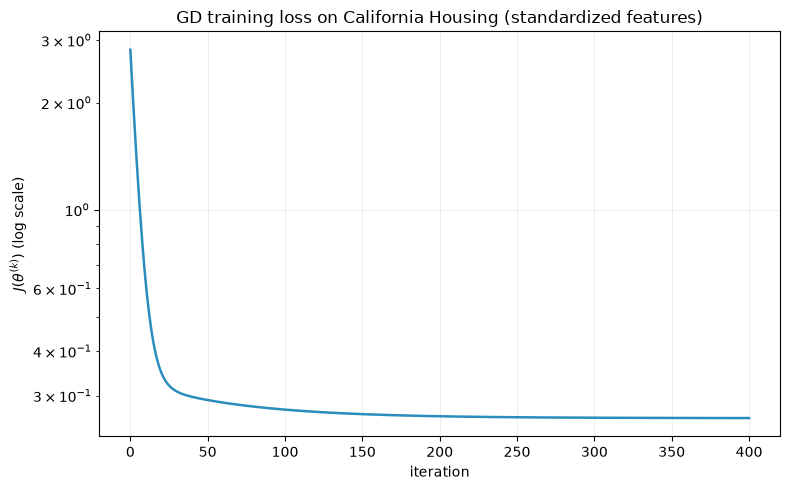

Test MSE  (scaled GD): 0.55580
Test RMSE (scaled GD): 0.74552


In [30]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(losses_scaled, color="#2b8cbe", linewidth=1.8)
ax.set_yscale("log")
ax.set_xlabel("iteration")
ax.set_ylabel(r"$J(\theta^{(k)})$ (log scale)")
ax.set_title("GD training loss on California Housing (standardized features)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# evaluate on the test set
y_pred = X_te_scaled @ theta_scaled
test_mse = float(np.mean((y_pred - y_te) ** 2))
print(f"Test MSE  (scaled GD): {test_mse:.5f}")
print(f"Test RMSE (scaled GD): {np.sqrt(test_mse):.5f}")

## 7. Why feature scaling matters

The California features have wildly different scales:

- `MedInc` $\sim \mathcal{O}(1)$
- `Population` $\sim \mathcal{O}(10^3)$

Without standardization, GD takes *huge* steps in the high-variance directions — the loss either **explodes** or converges extremely slowly.

We run the same code on **unstandardized** inputs to see it happen.

iter    0 | J = 1433990375.88970
[diverged] at iter 1


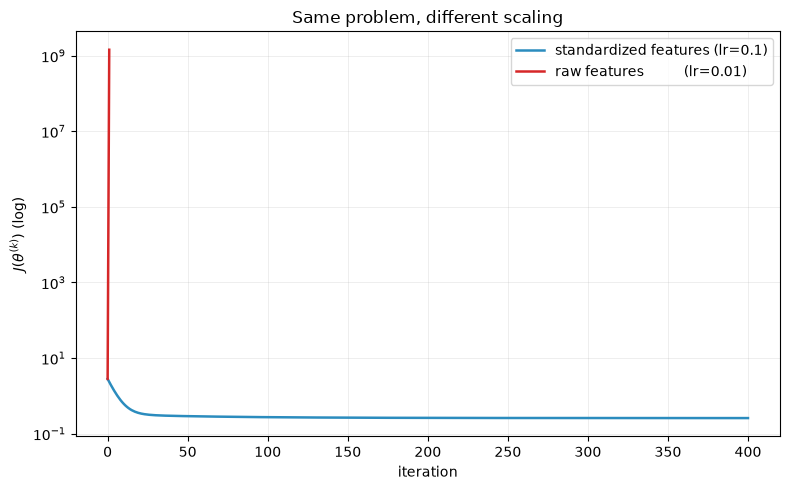

final loss, scaled   : 0.25920
final loss, unscaled : 1433990375.88970
ratio                : 5532447158.2×


In [31]:
theta_unscaled, losses_unscaled = train_gd(X_tr_b, y_tr, lr=0.01, n_iter=400, verbose_every=50)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(losses_scaled,   label="standardized features (lr=0.1)",  color="#2b8cbe", linewidth=1.8)
ax.plot(losses_unscaled, label="raw features          (lr=0.01)", color="#d62728", linewidth=1.8)
ax.set_yscale("log")
ax.set_xlabel("iteration")
ax.set_ylabel(r"$J(\theta^{(k)})$ (log)")
ax.set_title("Same problem, different scaling")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"final loss, scaled   : {losses_scaled[-1]:.5f}")
print(f"final loss, unscaled : {losses_unscaled[-1]:.5f}")
print(f"ratio                : {losses_unscaled[-1] / losses_scaled[-1]:.1f}×")

## 8. Summary

- **Linear regression** = fit $\theta$ so $h_\theta(x) = \theta^\top x$ matches $y$.
- **Squared-error loss** $J(\theta) = \frac{1}{2m}\|X\theta - y\|^2$ is a convex quadratic bowl.
- **Gradient descent** walks downhill using $\nabla J(\theta) = \frac{1}{m}X^\top(X\theta - y)$.
- The **surface plot** and **contours** make GD's behavior visible — the same code scales up to real data.
- **Feature scaling** is not optional: it dramatically changes GD's convergence.